In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## accuracy-vs-parameters

**Figure 1: MMLU accuracy versus model size for open models and ours.** The line connects the models on the accuracy–size Pareto front. Both our models lie on the front, and Ours-8B (77.4%) outperforms Gemma-2-27B (75.2%) and Mixtral-8x7B (70.6%), which are 3.4× and 5.9× larger.

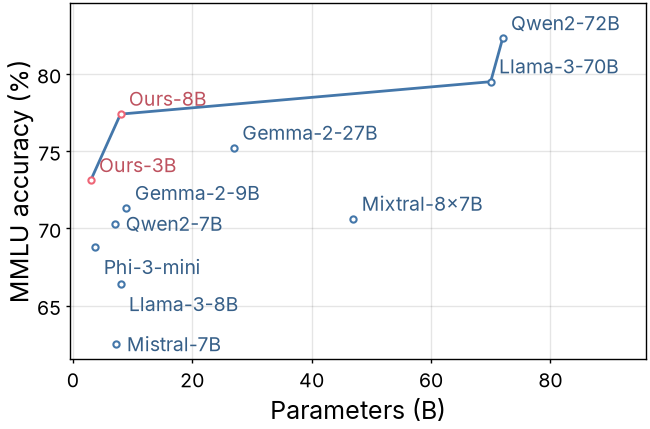

In [2]:
models = json.load(open("../accuracy-vs-parameters.json"))["models"]
front = ["Ours-3B", "Ours-8B", "Llama-3-70B", "Qwen2-72B"]
labels_beside = ["Qwen2-7B", "Mistral-7B"]
labels_below = ["Phi-3-mini", "Llama-3-8B"]

fig, ax = plt.subplots(figsize=(3.25, 2))
ax.plot([models[name]["params_b"] for name in front], [100 * models[name]["mmlu"] for name in front],
        color=colors["series-1"], zorder=1)
for name, m in models.items():
    color = colors["ours"] if name.startswith("Ours") else colors["series-1"]
    x, y = m["params_b"], 100 * m["mmlu"]
    ax.plot(x, y, "o", color=color)
    if name in labels_beside:
        ax.annotate(name, (x, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=7, color=darken(color))
    elif name in labels_below:
        ax.annotate(name, (x, y), xytext=(3, -3), textcoords="offset points", va="top", fontsize=7, color=darken(color))
    else:
        ax.annotate(name, (x, y), xytext=(3, 3), textcoords="offset points", fontsize=7, color=darken(color))
ax.set_xlabel("Parameters (B)")
ax.set_ylabel("MMLU accuracy (%)")

fit_height(fig, ax, aspect=0.618)
fig.savefig("accuracy-vs-parameters.pdf")
fig.savefig("accuracy-vs-parameters.png")
plt.show()

## t-sne

**Figure 2: t-SNE embedding of our encoder's features for 900 CIFAR-10 test images from six classes.** Each point is one image, colored by its class. The six classes form separate clusters, except cat and dog, which overlap in one shared region.

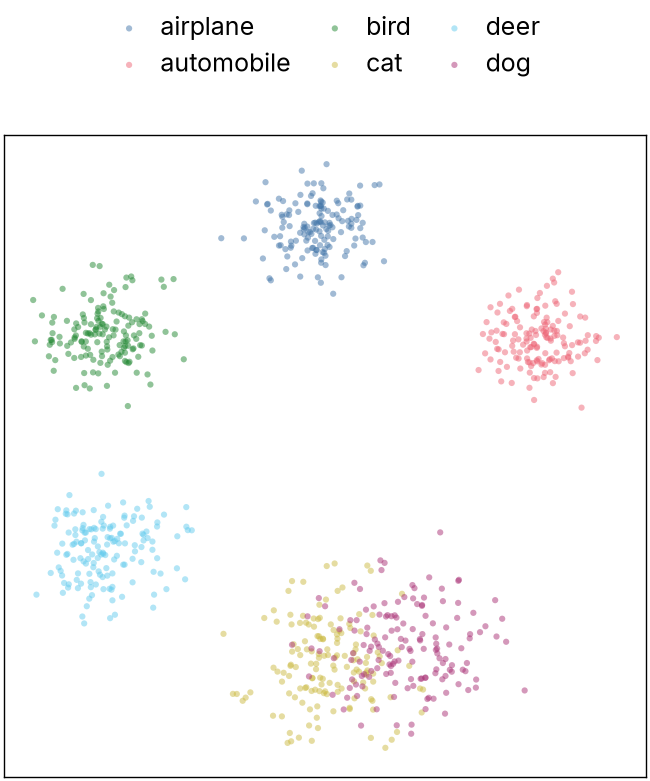

In [3]:
embedding = json.load(open("../t-sne.json"))

fig, ax = plt.subplots(figsize=(3.25, 3.25))
for i, (name, points) in enumerate(embedding.items()):
    ax.scatter(points["x"], points["y"], s=5, color=colors[f"series-{i + 1}"], edgecolors="none", alpha=0.5, label=name)
ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=2, frameon=False, ncol=3)

fit_height(fig, ax, aspect=1.0)
fig.savefig("t-sne.pdf")
fig.savefig("t-sne.png")
plt.show()